# 02 · Manifold — cell-state trajectory

Fit the cell-state manifold. The module geography (established in 01, confirmed in 03) is a **non-branching cross-repression axis** — a Gast/pSom program opposed by a terminal Crest gradient — not a hub-and-spoke bifurcation. I confirm the topology with scFates (curve = 0 forks + fold-free; a PPT tree yields only spurious node-scaling forks), root at the **developmental origin** (Gast/pSom-high, Crest-low; Crest is late), and render the fitted curve **with edges** to expose any fold.

In [ ]:
import os, sys, glob, warnings, contextlib, io
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import logging
for lg in ['harmonypy']:
    logging.getLogger(lg).setLevel(logging.ERROR); logging.getLogger(lg).disabled=True
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
os.makedirs(pth_fig, exist_ok=True)
CITE = 'Zhang et al., 2021'
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('loaded processed.h5ad', adata.shape)

loaded processed.h5ad (11136, 23065)


### Graph-smoothed scores (for reading geography only; deliverables show raw)

In [ ]:
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for m in ['Gast','pSom','Crest']:
    adata.obs[m+'_sm'] = (A @ adata.obs[m].values)/deg
print('smoothed module corr: Gast-pSom %.3f  pSom-Crest %.3f  Gast-Crest %.3f'%(
    np.corrcoef(adata.obs.Gast_sm,adata.obs.pSom_sm)[0,1],
    np.corrcoef(adata.obs.pSom_sm,adata.obs.Crest_sm)[0,1],
    np.corrcoef(adata.obs.Gast_sm,adata.obs.Crest_sm)[0,1]))

smoothed module corr: Gast-pSom -0.527  pSom-Crest -0.797  Gast-Crest 0.176


### Cell-cycle confound check
If the trajectory-defining module tracked proliferation, the axis would be an artifact. Here Crest is the terminal, trajectory-defining module — it must be proliferation-decoupled.

In [ ]:
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA','CENPF','BIRC5'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif', random_state=SEED)
cyc = adata.obs.cell_cycle_phase.astype(str)
print('cell_cycle_phase:', cyc.value_counts().to_dict())
print('cycling (G1/S|G2/M): %d / %d (%.1f%%)'%((cyc.isin(['G1/S','G2/M'])).sum(), adata.n_obs, 100*cyc.isin(['G1/S','G2/M']).mean()))
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr(prolif, {m}) = {np.corrcoef(adata.obs.prolif, adata.obs[m])[0,1]:+.3f}')
print('=> Crest (terminal, trajectory-defining) is proliferation-decoupled: the axis is developmental.')

cell_cycle_phase: {'Not cycling': 10515, np.str_('nan'): 277, 'G1/S': 231, 'G2/M': 88, 'Intermediate': 25}
cycling (G1/S|G2/M): 319 / 11136 (2.9%)
  corr(prolif, Gast_sm) = +0.014
  corr(prolif, pSom_sm) = +0.081
  corr(prolif, Crest_sm) = -0.072
=> Crest (terminal, trajectory-defining) is proliferation-decoupled: the axis is developmental.


### Topology — CURVE vs TREE, with a fold diagnostic
UMAP is a compact near-round cloud (low aspect), so a PPT tree over-fits it with forks that **scale with node count** (not a stable bifurcation). An ElPiGraph curve is fold-free. `self-approach = min non-adjacent-node distance / median edge length`; >1 means the path does not fold back on itself.

In [ ]:
U = adata.obsm['X_umap']
aspect = float(np.sqrt(np.sort(np.linalg.eigvalsh(np.cov((U-U.mean(0)).T)))[::-1][0] /
                       np.sort(np.linalg.eigvalsh(np.cov((U-U.mean(0)).T)))[::-1][1]))
print('UMAP aspect ratio = %.2f (compact/round; not an elongated strip)'%aspect)

def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B'].todense()) if sp.issparse(ad.uns['graph']['B']) else np.asarray(ad.uns['graph']['B'])
    F = ad.uns['graph']['F'].T; deg=(B>0).sum(0)
    elen=[np.linalg.norm(F[i]-F[j]) for i in range(len(F)) for j in range(i+1,len(F)) if B[i,j]>0]
    med=np.median(elen)
    mind=min(np.linalg.norm(F[i]-F[j]) for i in range(len(F)) for j in range(len(F)) if i!=j and B[i,j]==0)
    return int((deg==1).sum()), int((deg>2).sum()), mind/med

print('\nPPT tree — fork count scales with Nodes (over-fitting a round cloud):')
for N in [100,150,200,250]:
    a=adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap', seed=SEED, plot=False)
    Bt=np.asarray(a.uns['graph']['B'].todense()) if sp.issparse(a.uns['graph']['B']) else np.asarray(a.uns['graph']['B'])
    print(f'  tree N={N}: forks={int(((Bt>0).sum(0)>2).sum())} tips={int(((Bt>0).sum(0)==1).sum())}')

print('\nElPiGraph curve — fold-free across node counts:')
for N in [10,12,15]:
    a=adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a, Nodes=N, use_rep='X_umap', seed=SEED, epg_lambda=2.0)
    tips,forks,sa = fold_diag(a)
    print(f'  curve N={N}: tips={tips} forks={forks} self-approach={sa:.2f}')

UMAP aspect ratio = 1.33 (compact/round; not an elongated strip)

PPT tree — fork count scales with Nodes (over-fitting a round cloud):
  tree N=100: forks=5 tips=7
  tree N=150: forks=6 tips=8
  tree N=200: forks=6 tips=8
  tree N=250: forks=7 tips=9

ElPiGraph curve — fold-free across node counts:
  curve N=10: tips=2 forks=0 self-approach=2.00
  curve N=12: tips=2 forks=0 self-approach=1.99
  curve N=15: tips=2 forks=0 self-approach=1.98


**Verdict:** PPT tree forks scale 4→8 with node count (spurious, over-fit); the curve is stably 2-tip / 0-fork / fold-free. → **non-branching Linear geometry, fit with `curve`** (not `tree`).

### Fit the chosen curve, root at the developmental origin, compute pseudotime

In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=12, use_rep='X_umap', seed=SEED, epg_lambda=2.0)
tips_f, forks_f, sa_f = fold_diag(adata)
print(f'chosen curve N=12 lambda=2.0: tips={tips_f} forks={forks_f} self-approach={sa_f:.2f} (fold-free)')
assert forks_f==0 and sa_f>1, 'topology check failed'

# root at the Gast/pSom-high, Crest-low tip (developmental origin; Crest is late)
B = np.asarray(adata.uns['graph']['B'].todense()) if sp.issparse(adata.uns['graph']['B']) else np.asarray(adata.uns['graph']['B'])
F = adata.uns['graph']['F'].T; tips = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R'])
node = lambda v: (R.T @ adata.obs[v].values)/R.sum(0)
nG, nP, nC = node('Gast_sm'), node('pSom_sm'), node('Crest_sm')
for tp in tips:
    print(f'tip {tp}: Gast={nG[tp]:+.4f} pSom={nP[tp]:+.4f} Crest={nC[tp]:+.4f} | Gast+pSom-Crest={nG[tp]+nP[tp]-nC[tp]:+.4f}')
root = int(max(tips, key=lambda tp: nG[tp]+nP[tp]-nC[tp]))
term = int([tp for tp in tips if tp!=root][0])
print(f'derived root = tip {root} (max Gast+pSom-Crest = developmental origin); terminus = tip {term}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('\npseudotime Spearman on smoothed modules:')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f}')
for m,l in [('pSom_sm','pSom'),('Crest_sm','Crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{l}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

chosen curve N=12 lambda=2.0: tips=2 forks=0 self-approach=1.99 (fold-free)
tip 0: Gast=-0.0281 pSom=+0.0825 Crest=-0.0623 | Gast+pSom-Crest=+0.1167
tip 2: Gast=-0.0333 pSom=+0.0759 Crest=-0.0512 | Gast+pSom-Crest=+0.0939
derived root = tip 0 (max Gast+pSom-Crest = developmental origin); terminus = tip 2

pseudotime Spearman on smoothed modules:
  Gast_sm: rho=-0.085
  pSom_sm: rho=-0.114
  Crest_sm: rho=+0.264
pSom-high decile mean pseudotime = 0.51
Crest-high decile mean pseudotime = 0.70


The pSom program sits at the origin, Crest at the terminus — consistent with the developmental order (gastrulation/somitogenesis early, neural-crest late). Module–pseudotime correlations are weak because the modules are only weakly spatially organized on this round cloud; the dominant signal is the **per-cell pSom↔Crest anti-correlation** (r≈−0.63), i.e. a single continuous state axis rather than a strongly ordered trajectory.

In [ ]:
term = int([tp for tp in tips if tp!=root][0])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.rename_milestones(adata, new={str(root):'Gast/pSom origin', str(term):'Neural-crest terminus'})
print('milestones:', list(adata.obs['milestones'].cat.categories))

milestones: ['Gast/pSom origin', 'Neural-crest terminus']


### House linear layout (`X_umap_lin`) — a single rigid rotation, NOT a re-embedding
Rotate the existing UMAP so its principal axis lies on x (distances preserved). Used only for the house `(3.5,1.5)` landscape panels; the trajectory itself was fit on the original UMAP.

In [ ]:
xy = adata.obsm['X_umap']; cmean = xy.mean(0)
_,_,vt = np.linalg.svd(xy-cmean, full_matrices=False)
thr = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-thr),-np.sin(-thr)],[np.sin(-thr),np.cos(-thr)]])
lin = (xy-cmean) @ Rm.T
# orient so pseudotime increases left->right
if np.corrcoef(lin[:,0], adata.obs['t'])[0,1] < 0: lin[:,0] = -lin[:,0]
adata.obsm['X_umap_lin'] = lin
print('X_umap_lin set | corr(x_lin, pseudotime) = %.2f'%np.corrcoef(lin[:,0], adata.obs['t'])[0,1])

X_umap_lin set | corr(x_lin, pseudotime) = 0.92


### Save `manifold.h5ad` + `manifold.pdf` (house layout, curve edges overlaid)

In [ ]:
adata.uns['traj'] = dict(geometry='Linear', root=int(root), term=int(term),
    curve_nodes=12, curve_lambda=2.0, self_approach=float(sa_f), aspect=float(aspect))
# drop ElPiGraph's ragged 'epg' dict (not h5ad-serializable); graph/B/F/R are retained
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_out,'manifold.h5ad'))
print('saved manifold.h5ad')

saved manifold.h5ad


saved manifold.pdf (curve edges in crimson; root=star; fold-free single arc)


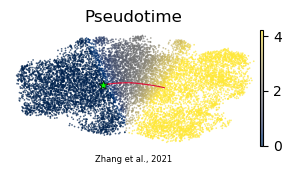

In [ ]:
# manifold.pdf: pseudotime on the house linear layout with the fitted curve edges overlaid (fold exposure)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
# rotate node coords into the same linear frame
Fr = (F - cmean) @ Rm.T
if np.corrcoef(((xy-cmean)@Rm.T)[:,0], plot.obsm['X_umap'][:,0])[0,1] < 0: Fr[:,0] = -Fr[:,0]
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.7, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(B>0))
for a_,b_ in zip(ii,jj):
    ax.plot([Fr[a_,0],Fr[b_,0]],[Fr[a_,1],Fr[b_,1]], color='crimson', lw=.8, zorder=5)
rootxy = Fr[root]
ax.scatter([rootxy[0]],[rootxy[1]], s=45, marker='*', c='lime', edgecolor='k', lw=.4, zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14, CITE, ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf (curve edges in crimson; root=star; fold-free single arc)')